
# EVChargeIQ
## EV Charging Infrastructure Analysis and Machine Learning

**Student:** Shanvi  
**Roll Number:** 2026010107  
**Programme:** MCA  
**Section:** 4  
**Academic Year:** 2026

---

## Project Objective

To analyze state-wise electric vehicle charging infrastructure in India, identify variations in infrastructure availability, study historical installation trends, and experiment with machine learning models to estimate future infrastructure expansion.

## Dataset

Ministry of Heavy Industries, Government of India.

## Tools and Technologies

- Python
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Plotly
- Streamlit

## Machine Learning Algorithms

1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [7]:

possible_paths = [
    Path.cwd() / "data" / "raw" / "charging_infrastructure.csv",
    Path.cwd().parent / "data" / "raw" / "charging_infrastructure.csv"
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Check data/raw/charging_infrastructure.csv"
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Dataset location: /home/shanvi/Projects/EVChargeIQ/data/raw/charging_infrastructure.csv
Rows: 36
Columns: 10


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational
0,Andaman and Nicobar,0,2,0,1,2,3,0,8,3
1,Andhra Pradesh,1,133,143,360,624,123,0,1384,1082
2,Arunachal Pradesh,2,6,23,19,6,0,1,55,46
3,Assam,7,39,119,186,173,2,0,526,461
4,Bihar,4,66,139,179,358,16,0,762,676


In [8]:

print("DATASET INFORMATION")
print("=" * 50)

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

print("\nStatistical summary:")
display(df.describe(include="all"))


DATASET INFORMATION

Dataset shape:
(36, 10)

Column names:
['state', 'FY20_21', 'FY21_22', 'FY22_23', 'FY23_24', 'FY24_25', 'FY25_26_partial', 'decommissioned', 'installed_total', 'operational']

Data types:
state                str
FY20_21            int64
FY21_22            int64
FY22_23            int64
FY23_24            int64
FY24_25            int64
FY25_26_partial    int64
decommissioned     int64
installed_total    int64
operational        int64
dtype: object

First five records:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational
0,Andaman and Nicobar,0,2,0,1,2,3,0,8,3
1,Andhra Pradesh,1,133,143,360,624,123,0,1384,1082
2,Arunachal Pradesh,2,6,23,19,6,0,1,55,46
3,Assam,7,39,119,186,173,2,0,526,461
4,Bihar,4,66,139,179,358,16,0,762,676



Last five records:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational
31,Tripura,2,13,16,24,8,0,0,63,55
32,Dadra and Nagar Haveli and Daman and Diu,0,1,5,4,5,3,0,18,8
33,Uttar Pradesh,19,252,649,1159,1034,171,0,3284,2893
34,Uttarakhand,5,24,43,93,81,8,0,254,211
35,West Bengal,0,141,216,326,496,29,0,1208,1039



Statistical summary:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational
count,36,36.00,36.00,36.00,36.00,36.00,36.00,36.00,36.00,36.00
unique,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Andaman and Nicobar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,8.72,65.11,129.39,212.47,312.25,42.97,0.44,770.47,632.03
std,NaN,11.98,69.22,160.87,257.60,346.80,56.06,2.50,864.03,723.81
min,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
25%,NaN,0.00,5.50,7.75,18.25,15.50,1.75,0.00,57.25,44.00
50%,NaN,4.00,38.00,69.00,96.50,184.50,17.00,0.00,476.50,392.50
75%,NaN,10.25,118.50,185.00,343.25,562.00,61.75,0.00,1384.75,1091.00


In [9]:

print("MISSING VALUE ANALYSIS")
print("=" * 50)

missing_values = df.isnull().sum()

display(
    pd.DataFrame({
        "Missing Values": missing_values,
        "Missing Percentage": (
            missing_values / len(df) * 100
        ).round(2)
    })
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate states:", df["state"].duplicated().sum())


MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
state,0,0.00
FY20_21,0,0.00
FY21_22,0,0.00
FY22_23,0,0.00
FY23_24,0,0.00
FY24_25,0,0.00
FY25_26_partial,0,0.00
decommissioned,0,0.00
installed_total,0,0.00
operational,0,0.00



Duplicate rows: 0

Duplicate states: 0


In [10]:

year_columns = [
    "FY20_21",
    "FY21_22",
    "FY22_23",
    "FY23_24",
    "FY24_25",
    "FY25_26_partial"
]

numeric_columns = year_columns + [
    "installed_total",
    "operational"
]

if "decommissioned" in df.columns:
    numeric_columns.append("decommissioned")

df["state"] = df["state"].astype(str).str.strip()

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Missing values after conversion:")
display(df[numeric_columns].isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate state names:")
display(df[df["state"].duplicated(keep=False)])

print("\nNegative values:")
display(df[(df[numeric_columns] < 0).any(axis=1)])

print("\nOperational greater than installed:")
display(
    df[df["operational"] > df["installed_total"]]
)


Missing values after conversion:


FY20_21            0
FY21_22            0
FY22_23            0
FY23_24            0
FY24_25            0
FY25_26_partial    0
installed_total    0
operational        0
decommissioned     0
dtype: int64


Duplicate rows: 0

Duplicate state names:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational



Negative values:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational



Operational greater than installed:


,state,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,FY25_26_partial,decommissioned,installed_total,operational


In [11]:

print("DATASET SUMMARY")
print("=" * 50)

print("Total state/UT records:", df["state"].nunique())

total_installed = df["installed_total"].sum()
total_operational = df["operational"].sum()

print("Net installed chargers:", total_installed)
print("Operational chargers:", total_operational)

operational_rate = (
    total_operational / total_installed
) * 100

print("Overall operationalization rate:",
      round(operational_rate, 2), "%")

print("\nAnnual gross installations:")

annual_totals = df[year_columns].sum()

display(annual_totals.to_frame("Gross Installations"))

print("\nTotal gross installations:", annual_totals.sum())
print("Net installed total:", total_installed)

print(
    "Difference between gross annual additions and net total:",
    annual_totals.sum() - total_installed
)


DATASET SUMMARY
Total state/UT records: 36
Net installed chargers: 27737
Operational chargers: 22753
Overall operationalization rate: 82.03 %

Annual gross installations:


,Gross Installations
FY20_21,314
FY21_22,2344
FY22_23,4658
FY23_24,7649
FY24_25,11241
FY25_26_partial,1547



Total gross installations: 27753
Net installed total: 27737
Difference between gross annual additions and net total: 16


In [12]:

long_df = pd.melt(
    df,
    id_vars=["state"],
    value_vars=year_columns,
    var_name="financial_year",
    value_name="installations"
)

print("Original dataset shape:", df.shape)
print("Transformed dataset shape:", long_df.shape)

display(long_df.head(15))


Original dataset shape: (36, 10)
Transformed dataset shape: (216, 3)


,state,financial_year,installations
0,Andaman and Nicobar,FY20_21,0
1,Andhra Pradesh,FY20_21,1
2,Arunachal Pradesh,FY20_21,2
3,Assam,FY20_21,7
4,Bihar,FY20_21,4
5,Chandigarh,FY20_21,6
6,Chhattisgarh,FY20_21,0
7,Delhi,FY20_21,35
8,Goa,FY20_21,8
9,Gujarat,FY20_21,11


,financial_year,installations
0,FY20_21,314
1,FY21_22,2344
2,FY22_23,4658
3,FY23_24,7649
4,FY24_25,11241
5,FY25_26_partial,1547


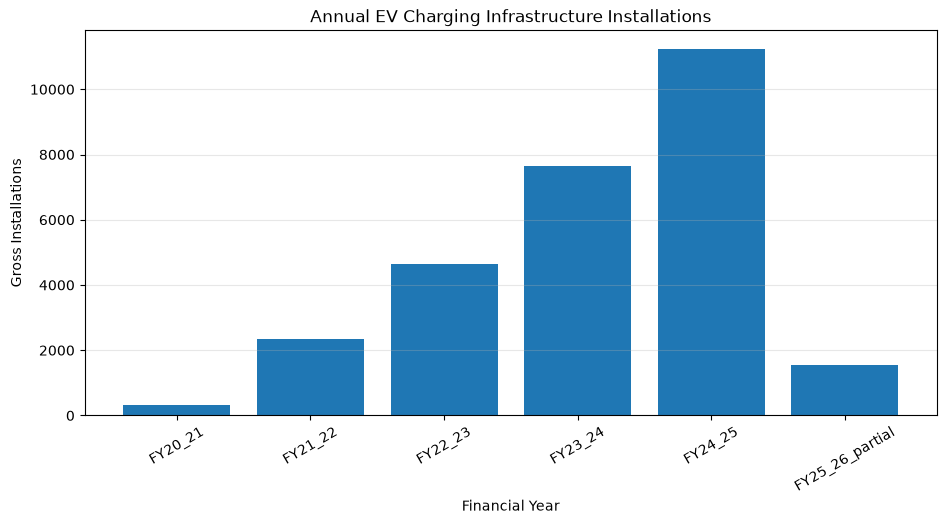

In [13]:

annual_analysis = (
    long_df.groupby("financial_year")["installations"]
    .sum()
    .reset_index()
)

display(annual_analysis)

plt.figure(figsize=(11, 5))

plt.bar(
    annual_analysis["financial_year"],
    annual_analysis["installations"]
)

plt.title("Annual EV Charging Infrastructure Installations")
plt.xlabel("Financial Year")
plt.ylabel("Gross Installations")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()


,state,installed_total,operational
33,Uttar Pradesh,3284,2893
14,Karnataka,2400,2039
19,Maharashtra,2243,1786
27,Rajasthan,1985,1740
29,Tamil Nadu,2286,1677
18,Madhya Pradesh,1417,1291
30,Telangana,1524,1173
10,Haryana,1387,1167
9,Gujarat,1488,1118
1,Andhra Pradesh,1384,1082


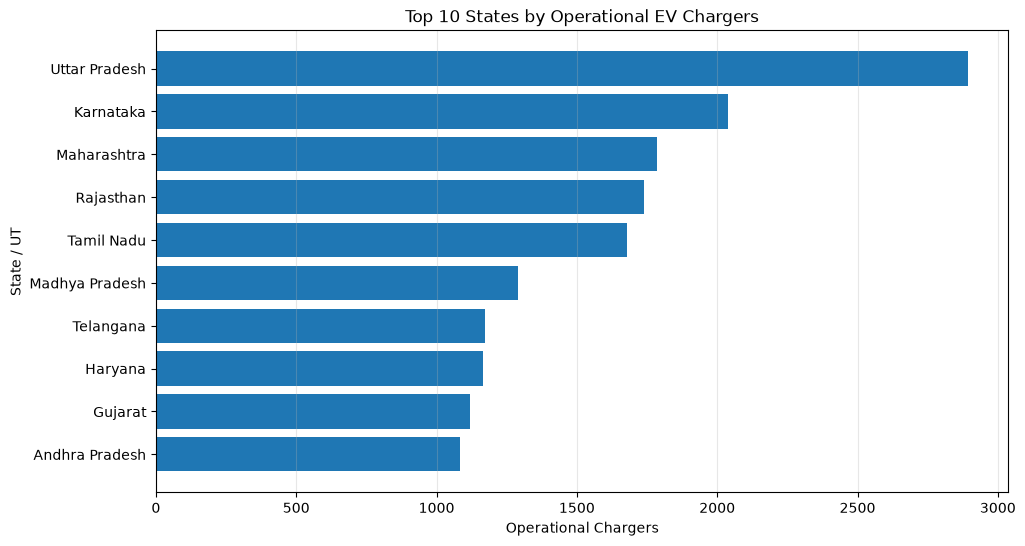

In [14]:

top_states = df.sort_values(
    by="operational",
    ascending=False
).head(10)

display(
    top_states[["state", "installed_total", "operational"]]
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_states["state"][::-1],
    top_states["operational"][::-1]
)

plt.title("Top 10 States by Operational EV Chargers")
plt.xlabel("Operational Chargers")
plt.ylabel("State / UT")
plt.grid(axis="x", alpha=0.3)

plt.show()


In [15]:

state_analysis = df.copy()

state_analysis["operationalization_rate"] = (
    state_analysis["operational"]
    / state_analysis["installed_total"].replace(0, np.nan)
) * 100

state_analysis["non_operational_difference"] = (
    state_analysis["installed_total"]
    - state_analysis["operational"]
)

display(
    state_analysis[
        [
            "state",
            "installed_total",
            "operational",
            "non_operational_difference",
            "operationalization_rate"
        ]
    ].sort_values(
        by="operationalization_rate",
        ascending=False
    ).round(2)
)


,state,installed_total,operational,non_operational_difference,operationalization_rate
17,Lakshadweep,1,1,0,100.00
5,Chandigarh,24,23,1,95.83
16,Ladakh,24,23,1,95.83
28,Sikkim,13,12,1,92.31
18,Madhya Pradesh,1417,1291,126,91.11
20,Manipur,71,64,7,90.14
4,Bihar,762,676,86,88.71
33,Uttar Pradesh,3284,2893,391,88.09
27,Rajasthan,1985,1740,245,87.66
3,Assam,526,461,65,87.64


,FY20_21,FY21_22,FY22_23,FY23_24,FY24_25,installed_total,operational
FY20_21,1.00,0.60,0.58,0.58,0.66,0.65,0.65
FY21_22,0.60,1.00,0.89,0.96,0.92,0.96,0.96
FY22_23,0.58,0.89,1.00,0.90,0.91,0.95,0.96
FY23_24,0.58,0.96,0.90,1.00,0.90,0.97,0.97
FY24_25,0.66,0.92,0.91,0.90,1.00,0.98,0.96
installed_total,0.65,0.96,0.95,0.97,0.98,1.00,1.00
operational,0.65,0.96,0.96,0.97,0.96,1.00,1.00


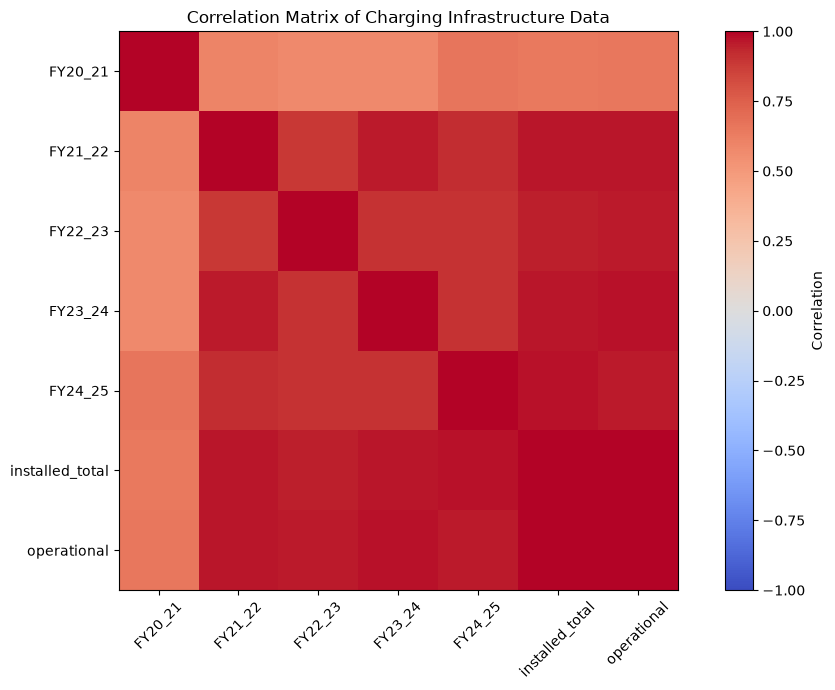

In [16]:

correlation_columns = [
    "FY20_21",
    "FY21_22",
    "FY22_23",
    "FY23_24",
    "FY24_25",
    "installed_total",
    "operational"
]

correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    interpolation="nearest",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Matrix of Charging Infrastructure Data")
plt.tight_layout()
plt.show()


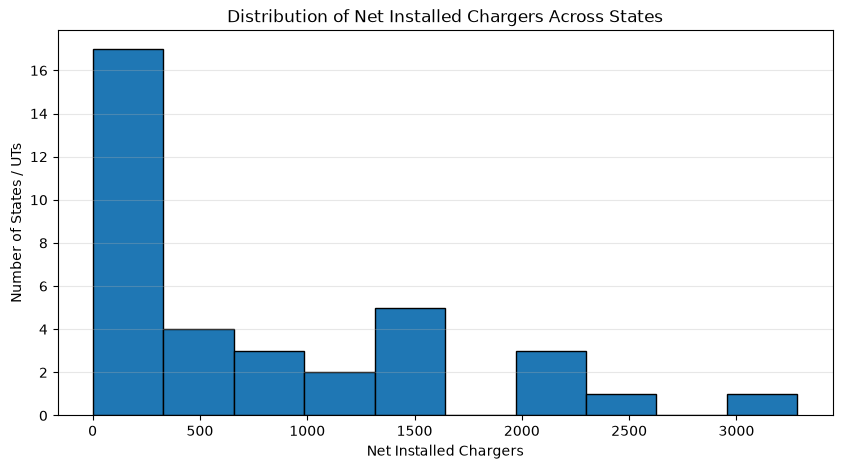

Mean: 770.4722222222222
Median: 476.5
Minimum: 1
Maximum: 3284
Standard deviation: 864.0288185045388


In [17]:

plt.figure(figsize=(10, 5))

plt.hist(
    df["installed_total"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Net Installed Chargers Across States")
plt.xlabel("Net Installed Chargers")
plt.ylabel("Number of States / UTs")
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Mean:", df["installed_total"].mean())
print("Median:", df["installed_total"].median())
print("Minimum:", df["installed_total"].min())
print("Maximum:", df["installed_total"].max())
print("Standard deviation:", df["installed_total"].std())


In [18]:

ml_records = []

full_years = year_columns[:5]

for _, row in df.iterrows():

    cumulative = 0

    for i in range(len(full_years) - 1):

        current_year = full_years[i]
        next_year = full_years[i + 1]

        current_installations = row[current_year]
        cumulative += current_installations

        ml_records.append({
            "state": row["state"],
            "year_index": i,
            "current_installations": current_installations,
            "cumulative_installations": cumulative,
            "next_year_installations": row[next_year]
        })

ml_dataset = pd.DataFrame(ml_records)

print("Machine Learning Dataset:")
print("Rows:", ml_dataset.shape[0])
print("Columns:", ml_dataset.shape[1])

display(ml_dataset.head(15))


Machine Learning Dataset:
Rows: 144
Columns: 5


,state,year_index,current_installations,cumulative_installations,next_year_installations
0,Andaman and Nicobar,0,0,0,2
1,Andaman and Nicobar,1,2,2,0
2,Andaman and Nicobar,2,0,2,1
3,Andaman and Nicobar,3,1,3,2
4,Andhra Pradesh,0,1,1,133
5,Andhra Pradesh,1,133,134,143
6,Andhra Pradesh,2,143,277,360
7,Andhra Pradesh,3,360,637,624
8,Arunachal Pradesh,0,2,2,6
9,Arunachal Pradesh,1,6,8,23


In [19]:

processed_folder = DATA_PATH.parents[1] / "processed"

processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

long_df.to_csv(
    processed_folder / "charging_infrastructure_long.csv",
    index=False
)

state_analysis.to_csv(
    processed_folder / "state_infrastructure_analysis.csv",
    index=False
)

ml_dataset.to_csv(
    processed_folder / "ml_training_dataset.csv",
    index=False
)

print("All processed datasets saved successfully!")

print("\nSaved files:")
for file in processed_folder.iterdir():
    print(file.name)


All processed datasets saved successfully!

Saved files:
state_infrastructure_analysis.csv
charging_infrastructure_long.csv
ml_training_dataset.csv



# EDA Findings and Conclusion

## Key Findings

1. The dataset contains 36 state and union territory records.
2. The net installed OMC charging infrastructure total is 27,737.
3. The total number of operational chargers is 22,753.
4. The overall operationalization rate is approximately 82%.
5. FY 2024-25 has the highest gross annual installations among the complete financial years.
6. FY 2025-26 data is partial through 1 March 2026.
7. Charging infrastructure is unevenly distributed across Indian states.
8. State-wise operationalization rates also vary.

## Data Preprocessing

- Loaded the original CSV using Pandas.
- Examined data types and dataset dimensions.
- Checked missing values and duplicate records.
- Converted numerical columns into numeric formats.
- Transformed the dataset from wide to long format.
- Created state-wise infrastructure indicators.
- Generated a supervised machine learning dataset.
- Exported processed datasets.

## Conclusion

The exploratory analysis reveals differences in EV charging infrastructure distribution and operationalization across Indian states and union territories.

The processed dataset provides a foundation for machine learning experiments to estimate subsequent-year OMC charging station installations.

A complete EV charging demand-gap analysis requires additional compatible state-wise EV registration data, which remains a future integration task.
